<a href="https://colab.research.google.com/github/Pal2786/Data-Analysis-Portfolio/blob/main/projects/operational-performance-analysis/Operational_Performance_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Total new cases: 546
Total resolved cases: 483
Net workload change: 63


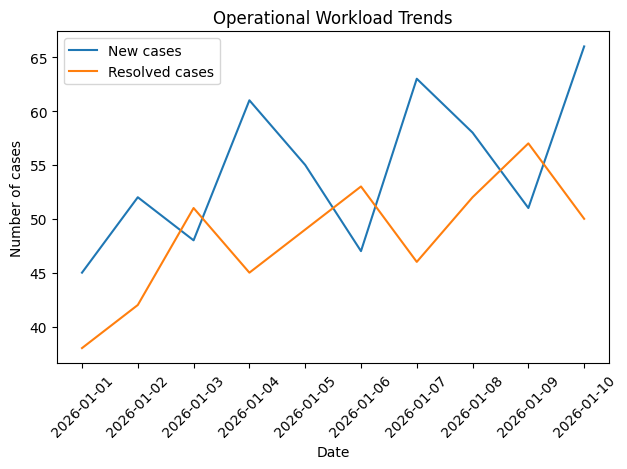

<Figure size 640x480 with 0 Axes>

In [ ]:

import urllib.request

base = (
    "https://raw.githubusercontent.com/"
    "Pal2786/Data-Analysis-Portfolio/main/"
    "projects/operational-performance-analysis/"
)

urllib.request.urlretrieve(
    base + "sample_data.csv", "sample_data.csv"
)
urllib.request.urlretrieve(
    base + "analysis.py", "analysis.py"
)

%run analysis.py


OPERATIONAL PERFORMANCE SUMMARY
Total new cases: 546
Total resolved cases: 483
Net workload change: +63
Throughput-to-intake ratio: 88.5%


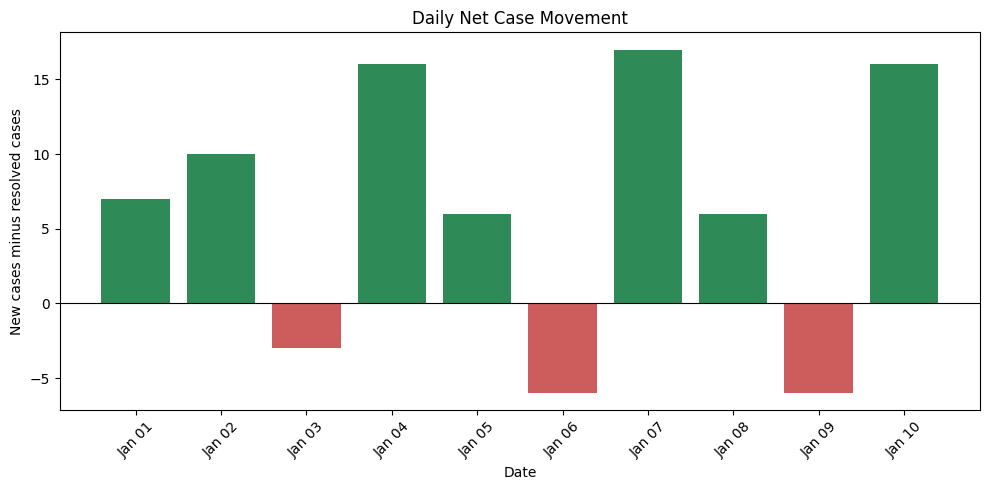

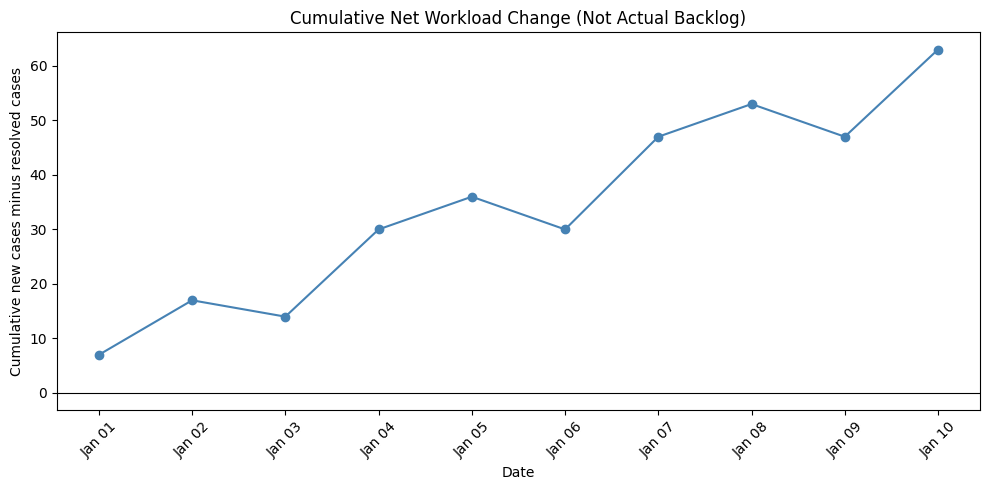

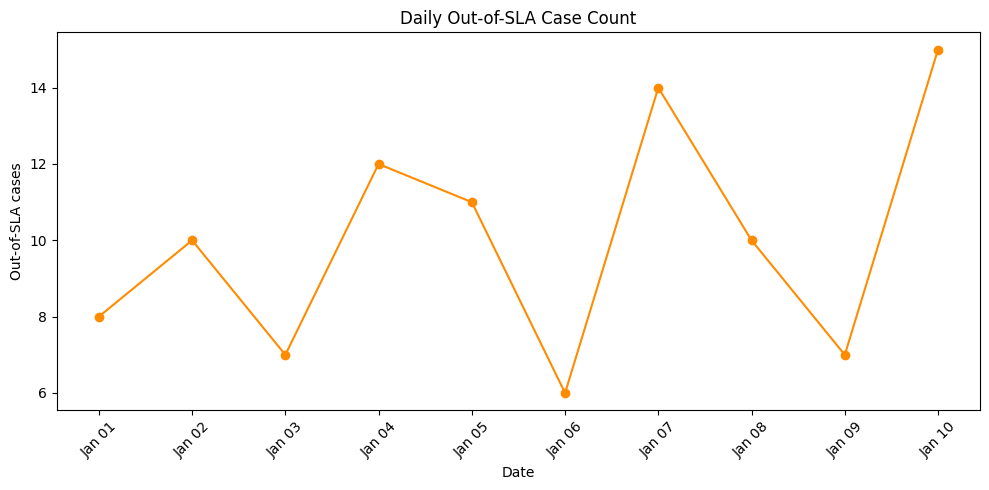


BUSINESS INSIGHTS
1. The team resolved 483 cases against 546 new cases. The throughput-to-intake ratio was 88.5%, with a net change of +63 cases over the period.
2. Daily net movement was positive on 7 of 10 days and negative on 3 days. The largest daily increase was +17 cases on 2026-01-07.
3. The sum of the daily out-of-SLA counts was 100. This does not necessarily represent unique cases. The highest daily count was 15 on 2026-01-10.

Charts saved:
- /content/daily_net_movement.png
- /content/cumulative_net_change.png
- /content/out_of_sla_trend.png


In [2]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd


# 1. Find and load the CSV
# This works with %run analysis.py in Colab when the CSV is beside analysis.py.
project_folder = Path.cwd()

csv_path = project_folder / "sample_data.csv"

if not csv_path.exists():
    raise FileNotFoundError(
        f"Could not find sample_data.csv in: {project_folder}"
    )

df = pd.read_csv(csv_path)

# 2. Check that all required columns exist
required_columns = [
    "date",
    "new_cases",
    "resolved_cases",
    "out_of_sla",
]

missing_columns = [
    column for column in required_columns
    if column not in df.columns
]

if missing_columns:
    raise ValueError(
        f"CSV is missing required columns: {missing_columns}"
    )

if df.empty:
    raise ValueError("The CSV has no data rows to analyze.")


# 3. Validate missing values, duplicates, dates, and counts
validation_errors = []

missing_counts = df[required_columns].isna().sum()
columns_with_missing_values = missing_counts[missing_counts > 0]

if not columns_with_missing_values.empty:
    missing_details = ", ".join(
        f"{column} ({count})"
        for column, count in columns_with_missing_values.items()
    )
    validation_errors.append(
        f"Missing values found: {missing_details}"
    )

# Convert the date text into actual dates.
parsed_dates = pd.to_datetime(df["date"], errors="coerce")
invalid_date_rows = df["date"].notna() & parsed_dates.isna()

if invalid_date_rows.any():
    row_numbers = (df.index[invalid_date_rows] + 2).tolist()
    validation_errors.append(
        f"Invalid dates in CSV row(s): {row_numbers}"
    )

valid_dates = parsed_dates.dropna()
duplicate_dates = valid_dates[
    valid_dates.duplicated(keep=False)
].unique()

if len(duplicate_dates) > 0:
    duplicate_date_text = [
        date.strftime("%Y-%m-%d")
        for date in duplicate_dates
    ]
    validation_errors.append(
        f"Duplicate dates found: {duplicate_date_text}"
    )

duplicate_rows = df.duplicated(keep=False)

if duplicate_rows.any():
    row_numbers = (df.index[duplicate_rows] + 2).tolist()
    validation_errors.append(
        f"Duplicate full rows found at CSV row(s): {row_numbers}"
    )

# Convert and validate the three case-count columns.
count_columns = [
    "new_cases",
    "resolved_cases",
    "out_of_sla",
]

numeric_data = {}

for column in count_columns:
    numeric_values = pd.to_numeric(df[column], errors="coerce")

    invalid_numeric_rows = (
        df[column].notna()
        & numeric_values.isna()
    )

    if invalid_numeric_rows.any():
        row_numbers = (
            df.index[invalid_numeric_rows] + 2
        ).tolist()
        validation_errors.append(
            f"Non-numeric values in '{column}' "
            f"at CSV row(s): {row_numbers}"
        )

    negative_values = (
        numeric_values.notna()
        & (numeric_values < 0)
    )

    if negative_values.any():
        row_numbers = (
            df.index[negative_values] + 2
        ).tolist()
        validation_errors.append(
            f"Negative values in '{column}' "
            f"at CSV row(s): {row_numbers}"
        )

    # Decimal case counts are invalid because cases must be whole numbers.
    decimal_values = (
        numeric_values.notna()
        & (numeric_values != numeric_values.astype("int64"))
    )

    if decimal_values.any():
        row_numbers = (
            df.index[decimal_values] + 2
        ).tolist()
        validation_errors.append(
            f"Decimal values in '{column}' "
            f"at CSV row(s): {row_numbers}"
        )

    numeric_data[column] = numeric_values

# Stop before analysis if any validation errors were found.
if validation_errors:
    error_details = "\n- ".join(validation_errors)
    raise ValueError(
        f"Please fix these data problems:\n- {error_details}"
    )

# Use the validated date and count columns.
df["date"] = parsed_dates

for column in count_columns:
    df[column] = numeric_data[column].astype("int64")

# Sort before calculating trends and cumulative values.
df = df.sort_values("date").reset_index(drop=True)


# 4. Calculate KPIs
df["net_movement"] = (
    df["new_cases"] - df["resolved_cases"]
)
df["cumulative_net_change"] = (
    df["net_movement"].cumsum()
)

total_new_cases = df["new_cases"].sum()
total_resolved_cases = df["resolved_cases"].sum()
net_workload_change = (
    total_new_cases - total_resolved_cases
)

if total_new_cases == 0:
    throughput_to_intake_ratio = None
else:
    throughput_to_intake_ratio = (
        total_resolved_cases / total_new_cases
    )

print("OPERATIONAL PERFORMANCE SUMMARY")
print(f"Total new cases: {total_new_cases:,.0f}")
print(f"Total resolved cases: {total_resolved_cases:,.0f}")
print(f"Net workload change: {net_workload_change:+,.0f}")

if throughput_to_intake_ratio is None:
    print(
        "Throughput-to-intake ratio: "
        "undefined (there were no new cases)"
    )
else:
    print(
        "Throughput-to-intake ratio: "
        f"{throughput_to_intake_ratio:.1%}"
    )


# 5. Configure readable date labels
def format_date_axis(axis):
    """Format a chart axis with compact date labels."""
    axis.xaxis.set_major_locator(mdates.AutoDateLocator())
    axis.xaxis.set_major_formatter(
        mdates.DateFormatter("%b %d")
    )
    axis.tick_params(axis="x", rotation=45)


# 6. Create daily net movement chart
fig, ax = plt.subplots(figsize=(10, 5))

bar_colors = [
    "seagreen"
    if movement >= 0
    else "indianred"
    for movement in df["net_movement"]
]

ax.bar(
    df["date"],
    df["net_movement"],
    color=bar_colors,
)

ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Daily Net Case Movement")
ax.set_xlabel("Date")
ax.set_ylabel("New cases minus resolved cases")
format_date_axis(ax)

fig.tight_layout()
fig.savefig(
    project_folder / "daily_net_movement.png",
    dpi=150,
)

plt.show()
plt.close(fig)


# 7. Create cumulative net workload change chart
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    df["date"],
    df["cumulative_net_change"],
    marker="o",
    color="steelblue",
)

ax.axhline(0, color="black", linewidth=0.8)
ax.set_title(
    "Cumulative Net Workload Change "
    "(Not Actual Backlog)"
)
ax.set_xlabel("Date")
ax.set_ylabel(
    "Cumulative new cases minus resolved cases"
)
format_date_axis(ax)

fig.tight_layout()
fig.savefig(
    project_folder / "cumulative_net_change.png",
    dpi=150,
)

plt.show()
plt.close(fig)


# 8. Create out-of-SLA count trend chart
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    df["date"],
    df["out_of_sla"],
    marker="o",
    color="darkorange",
)

ax.set_title("Daily Out-of-SLA Case Count")
ax.set_xlabel("Date")
ax.set_ylabel("Out-of-SLA cases")
format_date_axis(ax)

fig.tight_layout()
fig.savefig(
    project_folder / "out_of_sla_trend.png",
    dpi=150,
)

plt.show()
plt.close(fig)


# 9. Print three business insights
days_with_net_increase = int(
    (df["net_movement"] > 0).sum()
)
days_with_net_decrease = int(
    (df["net_movement"] < 0).sum()
)

highest_net_day = df.loc[
    df["net_movement"].idxmax()
]

highest_sla_day = df.loc[
    df["out_of_sla"].idxmax()
]

total_out_of_sla_entries = df["out_of_sla"].sum()

print("\nBUSINESS INSIGHTS")

if throughput_to_intake_ratio is None:
    print(
        "1. There were no incoming cases, so a "
        "throughput-to-intake ratio cannot be calculated."
    )
else:
    print(
        f"1. The team resolved {total_resolved_cases:,.0f} "
        f"cases against {total_new_cases:,.0f} new cases. "
        f"The throughput-to-intake ratio was "
        f"{throughput_to_intake_ratio:.1%}, with a net "
        f"change of {net_workload_change:+,.0f} cases "
        f"over the period."
    )

print(
    f"2. Daily net movement was positive on "
    f"{days_with_net_increase} of {len(df)} days and "
    f"negative on {days_with_net_decrease} days. "
    f"The largest daily increase was "
    f"{highest_net_day['net_movement']:+,.0f} cases "
    f"on {highest_net_day['date']:%Y-%m-%d}."
)

print(
    f"3. The sum of the daily out-of-SLA counts was "
    f"{total_out_of_sla_entries:,.0f}. This does not "
    f"necessarily represent unique cases. The highest "
    f"daily count was "
    f"{highest_sla_day['out_of_sla']:,.0f} "
    f"on {highest_sla_day['date']:%Y-%m-%d}."
)

print("\nCharts saved:")
print(
    f"- {project_folder / 'daily_net_movement.png'}"
)
print(
    f"- {project_folder / 'cumulative_net_change.png'}"
)
print(
    f"- {project_folder / 'out_of_sla_trend.png'}"
)